<h1 align="center"> Part1: Data Expolaration and Visualization</h1>

Q1: Load the dataset and display the first 5 rows

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
data=pd.read_csv("lifesat.csv")
data.head()

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.387938,5.8
1,Greece,27287.083401,5.4
2,Turkey,28384.987785,5.5
3,Latvia,29932.493910,5.9
4,Hungary,31007.768407,5.6


Q2: Print basic info and summary statistics

In [2]:
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country               27 non-null     str    
 1   GDP per capita (USD)  27 non-null     float64
 2   Life satisfaction     27 non-null     float64
dtypes: float64(2), str(1)
memory usage: 983.0 bytes


,GDP per capita (USD),Life satisfaction
count,27.000000,27.000000
mean,41564.521771,6.566667
std,9631.452319,0.765607
min,26456.387938,5.400000
25%,33938.289305,5.900000
50%,41627.129269,6.800000
75%,49690.580269,7.300000
max,60235.728492,7.600000


Q3: Display a scatter plot for GDP per capita vs Life Satisfaction . Add labels, title, and discuss the observed relationship

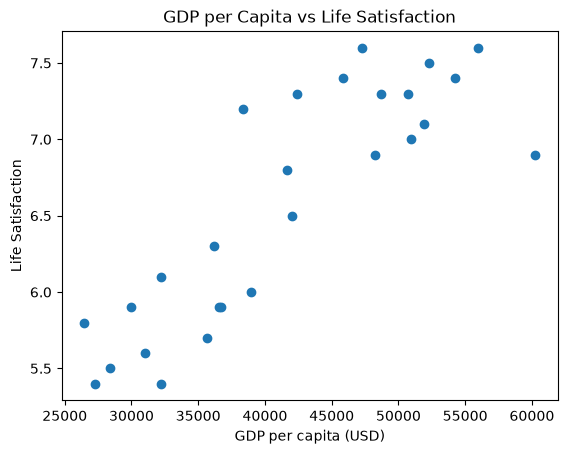

In [3]:
plt.scatter(data["GDP per capita (USD)"], data["Life satisfaction"])
plt.xlabel("GDP per capita (USD)") 
plt.ylabel("Life Satisfaction") 
plt.title("GDP per Capita vs Life Satisfaction") 
plt.show()

Discussion The scatter plot shows a positive relationship between GDP per capita and Life Satisfaction. In general, countries with higher GDP per capita tend to have higher life satisfaction.

<h1 align="center">Part2:Linear Regression Model</h1>

Q4 : Extract input (X) and target (y). Print their shapes.


In [4]:
X = data[["GDP per capita (USD)"]]
y = data["Life satisfaction"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (27, 1)
Shape of y: (27,)


Q5 :Train a Linear Regression model & Display coefficient and intercept.

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X, y)

print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

Coefficient: 6.778899694341222e-05
Intercept: 3.7490494273769093


Q6 : Plot the predicted regression line from the model along with a scatter plot of the data

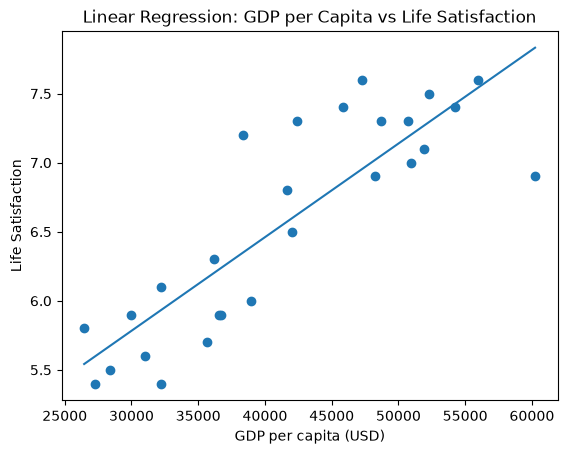

In [6]:
y_pred = model.predict(X)

plt.scatter(X, y)

plt.plot(X, y_pred)

plt.xlabel("GDP per capita (USD)")
plt.ylabel("Life Satisfaction")
plt.title("Linear Regression: GDP per Capita vs Life Satisfaction")

plt.show()

Q7 :Predict Life Satisfaction for GDP = 37,655.2 USD. Comment on result.


In [9]:
gdp_value = [[37655.2]]

prediction = model.predict(gdp_value)

print("Predicted Life Satisfaction:", prediction[0])

Predicted Life Satisfaction: 6.301657665080485


c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


<h1 align="center"> Part 3: K-Nearest Neighbors Regression</h1>

Q8 : Train a KNeighborsRegressor (n_neighbors=3).


In [10]:
from sklearn.neighbors import KNeighborsRegressor

knn_model = KNeighborsRegressor(n_neighbors=3)

knn_model.fit(X, y)

print("KNN model trained with 3 neighbors.")

KNN model trained with 3 neighbors.


Q9 : Predict Life Satisfaction for GDP = 37,655.2 USD and compare with Linear Regression.

In [11]:
knn_prediction = knn_model.predict([[37655.2]])

linear_prediction = model.predict([[37655.2]])

print("KNN Prediction:", round(knn_prediction[0], 2))
print("Linear Regression Prediction:", round(linear_prediction[0], 2))

KNN Prediction: 6.33
Linear Regression Prediction: 6.3


c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Comparison
The KNN model predicts a Life Satisfaction of approximately 6.33, while the Linear Regression model predicts approximately 6.30.
The two predictions are close

Q10 :Use n_neighbors 1, 3, 5, and 10 and print the predicted values of life satisfaction in Q10. Plot the results using a line plot.

In [12]:
neighbors = [1, 3, 5, 10]

predictions = []

for k in neighbors:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X, y)
    
    prediction = knn.predict([[37655.2]])
    predictions.append(prediction[0])

for k, prediction in zip(neighbors, predictions):
    print("n_neighbors =", k, 
          "Predicted Life Satisfaction =", round(prediction, 2))

n_neighbors = 1 Predicted Life Satisfaction = 7.2
n_neighbors = 3 Predicted Life Satisfaction = 6.33
n_neighbors = 5 Predicted Life Satisfaction = 6.26
n_neighbors = 10 Predicted Life Satisfaction = 6.37


c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
c:\Users\77082\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


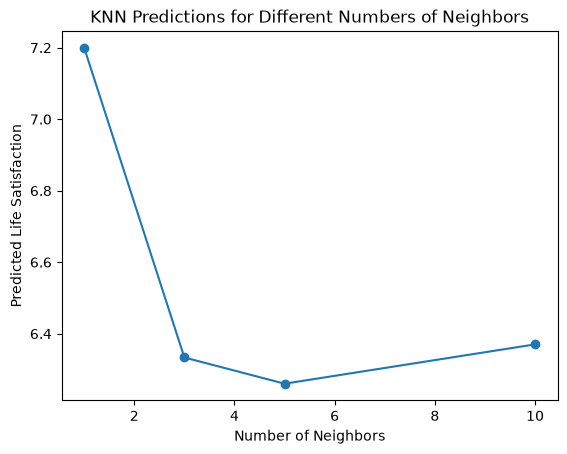

In [13]:
plt.plot(neighbors, predictions, marker="o")
plt.xlabel("Number of Neighbors")
plt.ylabel("Predicted Life Satisfaction")
plt.title("KNN Predictions for Different Numbers of Neighbors")

plt.show()

Conclusion
The analysis shows a positive relationship between GDP per capita and Life Satisfaction, both models can be used to predict Life Satisfaction from GDP per capita, but they use different approaches.